In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from functools import reduce
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
  "font.size": 9,
  "axes.titlesize": 9,
  "axes.labelsize": 9,
  "xtick.labelsize": 9,
  "ytick.labelsize": 9,
  "legend.fontsize": 9
})

In [2]:
def expand_time(weights, time_step = 0.025, sample_time_step = 0.5, max_time = None):
  synapse_cols = [ f"Synapse{id}" for id in range(0, 10) ]
  time = weights.Time
  weights_to_update = weights.copy()[ synapse_cols ]

  if max_time is None:
    max_time = time.max()

  time = (time / time_step).round() * time_step
  weights_to_update.index = time

  new_time = np.arange(0, max_time + time_step, time_step)
  new_weights = pd.DataFrame(weights_to_update).set_index(time).reindex(new_time, method = "ffill")

  if time_step == sample_time_step:
    return new_weights

  # sample every sample_time_step
  sampled_time = np.arange(0, max_time, sample_time_step)
  new_weights = new_weights.loc[sampled_time]

  return new_weights

In [3]:
def read_weights(stimulation, cell_ids, frequency):
  weights = []
  for cell_id in cell_ids:
    filename = f"output/temporal-interference-1/{cell_id}/random_poisson/{frequency}/{stimulation}/synapse_weights.csv"
    synapse_weights = pd.read_csv(filename, index_col = 0)
    synapse_weights = expand_time(synapse_weights, time_step = 0.025, sample_time_step = 0.025, max_time = 10_000)

    synapse_columns = [ f"Synapse{id}" for id in range(0, 10) ]
    synapse_weights = synapse_weights.rename(columns = { synapse: f"{synapse}_cell{cell_id}" for synapse in synapse_columns })

    weights.append(synapse_weights)
  
  weights = reduce(lambda left, right: pd.merge(left, right, on = "Time", how = "inner"), weights)

  return weights

In [4]:
def read_all_frequencies(cell_ids, frequencies, stimulation):
  weights = {}

  for frequency in frequencies:
    print(f"Processing frequency {frequency} Hz")
    weights[ frequency ] = read_weights(stimulation, cell_ids, frequency)
  
  return weights

In [5]:
carrier = 1000
beat = 5
amplitudes = [ 0.5, 0.9 ]
frequencies = np.arange(1, 26)
cell_ids = np.arange(0, 20)

stimulations = [
  "No tTIS",
  "50% tTIS",
  "90% tTIS"
]

colors = {
  "No tTIS": "#0D0887",
  "50% tTIS": "#E16462",
  "90% tTIS": "#B12A90"
}

weights = {
  "No tTIS": read_all_frequencies(cell_ids, frequencies, "noTI_0.1"),
  "50% tTIS": read_all_frequencies(cell_ids, frequencies, "1000_5_0.5_0.1"),
  "90% tTIS": read_all_frequencies(cell_ids, frequencies, "1000_5_0.9_0.1"),
}


Processing frequency 1 Hz
Processing frequency 2 Hz
Processing frequency 3 Hz
Processing frequency 4 Hz
Processing frequency 5 Hz
Processing frequency 6 Hz
Processing frequency 7 Hz
Processing frequency 8 Hz
Processing frequency 9 Hz
Processing frequency 10 Hz
Processing frequency 11 Hz
Processing frequency 12 Hz
Processing frequency 13 Hz
Processing frequency 14 Hz
Processing frequency 15 Hz
Processing frequency 16 Hz
Processing frequency 17 Hz
Processing frequency 18 Hz
Processing frequency 19 Hz
Processing frequency 20 Hz
Processing frequency 21 Hz
Processing frequency 22 Hz
Processing frequency 23 Hz
Processing frequency 24 Hz
Processing frequency 25 Hz
Processing frequency 1 Hz
Processing frequency 2 Hz
Processing frequency 3 Hz
Processing frequency 4 Hz
Processing frequency 5 Hz
Processing frequency 6 Hz
Processing frequency 7 Hz
Processing frequency 8 Hz
Processing frequency 9 Hz
Processing frequency 10 Hz
Processing frequency 11 Hz
Processing frequency 12 Hz
Processing frequenc

In [6]:
def read_stimuli(cell_id, rate):
  stimuli = pd.read_csv(
    f"output/temporal-interference-1/{cell_id}/random_poisson/{rate}/noTI_0.1/synapse_stimuli.csv",
    header = None
  )
  stimuli = stimuli.fillna('').values.tolist()
  stimuli = [[x for x in row if x != ""] for row in stimuli]

  return stimuli

In [7]:
def format_ax(ax, grid = True):
  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)

  for spine in ax.spines.values():
    spine.set_color("gray")

  ax.tick_params(axis="both", colors="#1a1a1a")

  if grid:
    ax.grid(alpha = 0.5, zorder = 0)

In [8]:
def plot_stimuli(ax, stimuli):
  synapse_stimuli = np.array(stimuli) / 1000
  ax.eventplot(synapse_stimuli, linelengths = 0.75, colors = "black", linewidths = 0.5)

  ax.set_ylim(0.5, 1.5)
  ax.set_xlim(0, 10)
  ax.tick_params(left = False, labelleft = False, bottom = False, labelbottom = False)

  for spine in ax.spines:
    ax.spines[spine].set_visible(False)

In [9]:
synapse_number = 0
cell_id = 0

synapse_id = f"Synapse{synapse_number}_cell{cell_id}"

selected_frequencies = [1, 5, 15]

stimuli = {}
for f in selected_frequencies:
  stimuli[f] = read_stimuli(cell_id, f)[synapse_number]

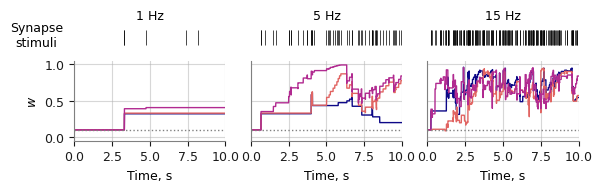

In [10]:
fig, axs = plt.subplots(nrows = 2, ncols = 3, figsize = (6, 2), sharex = True, height_ratios = [0.2, 0.8])

for ax, f in zip(axs[1], selected_frequencies):
  for stimulation in weights.keys():    
    w = weights[stimulation][f][synapse_id]

    ax.plot(
      w.index / 1000,
      w.values,
      color = colors[stimulation],
      linewidth = 1
    )

  format_ax(ax)
  ax.set_ylim(-0.05, 1.05)
  ax.set_ylabel(rf"$w$")
  ax.set_xlabel("Time, s")

  ax.axhline(y = 0.1, linestyle = ":", linewidth = 1, color = "gray")

for ax in axs[1][1:3]:
  ax.set_ylabel("")
  ax.tick_params(left = False, labelleft = False)

for ax, f in zip(axs[0], selected_frequencies):
  plot_stimuli(ax, stimuli[f])
  ax.set_title(f"{f} Hz")

axs[0][0].set_ylabel("Synapse\nstimuli", rotation = 0)
axs[0][0].yaxis.set_label_coords(-0.25, -0.1)

plt.tight_layout()
plt.show()

In [11]:
gained_weights_all = []
for stimulation in ["50% tTIS", "90% tTIS"]:
  for f in frequencies:
    time_points = weights[stimulation][f].index > 9.5 * 1000
    change_ti = np.abs(weights[stimulation][f].iloc[time_points, :] - 0.1).mean(axis = 0)
    change_noti = np.abs(weights["No tTIS"][f].iloc[time_points, :] - 0.1).mean(axis = 0)
    difference = change_ti - change_noti

    stat, p = stats.wilcoxon(change_noti, change_ti)
    gained_weights_all.append(
      pd.DataFrame({
        "Frequency": [f],
        "Stimulation": stimulation,
        "Mean": np.mean(difference),
        "Error": difference.std() / np.sqrt(difference.shape[0]),
        "P": p
      })
    )

gained_weights_all = pd.concat(gained_weights_all, ignore_index = True)

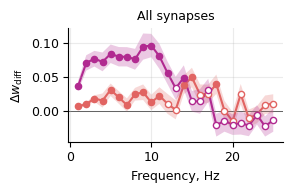

In [12]:
gained_weights = gained_weights_all
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (3, 2))
ax = axs

ax.axhline(y = 0, linestyle = "-", linewidth = 0.5, color = "black", zorder = 0)

for stimulation in ["50% tTIS", "90% tTIS"]:
  dt = gained_weights[gained_weights.Stimulation == stimulation]
  sig = dt[dt.P < 0.05]
  nonsig = dt[dt.P >= 0.05]

  ax.plot(
    dt.Frequency, dt.Mean,
    color = colors[stimulation],
    zorder = 1
  )

  ax.fill_between(
    dt.Frequency,
    dt.Mean - dt.Error,
    dt.Mean + dt.Error,
    alpha = 0.25,
    color = colors[stimulation],
    edgecolor = None
  )

  ax.scatter(
    sig.Frequency,
    sig.Mean,
    color = colors[stimulation],
    label = stimulation,
    s = 20,
    zorder = 3
  )

  ax.scatter(
    nonsig.Frequency,
    nonsig.Mean,
    facecolors = "white",
    edgecolors = colors[stimulation],
    s = 20,
    alpha = 1,
    zorder = 5
  )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(alpha = 0.25)
ax.set_ylabel(r"$\Delta w_{\text{diff}}$")
# ax.set_ylabel("Mean\n" + r"$\Delta w_{\text{tTIS}} - \Delta w_{\text{No tTIS}}$")
ax.set_xlabel("Frequency, Hz")

legend_elements = [
  Line2D([0], [0], marker = "o", color = "k", markerfacecolor = "k", markersize = 3, linestyle = "None", label = "Significant"),
  Line2D([0], [0], marker = "o", color = "k", markerfacecolor = "none", markersize = 3, linestyle = "None", label = "Not significant"),
]

# ax.legend(
#   title = "Significance\n(P < 0.05)",
#   handles = legend_elements,
#   loc = "center right",
#   ncols = 1,
#   frameon = False,
#   bbox_to_anchor = (1, 0.85),
#   handletextpad = 0.25
# )

ax.set_title("All synapses")

plt.tight_layout()
plt.show()

In [13]:
gained_weights_ltp = []

for stimulation in ["50% tTIS", "90% tTIS"]:
  for f in frequencies:
    time_points = weights[stimulation][f].index > 9.5 * 1000
    final_weights_ti = weights[stimulation][f].iloc[time_points, :].mean(axis = 0)
    final_weights_noti = weights["No tTIS"][f].iloc[time_points, :].mean(axis = 0)

    synapses = list(
      set(np.where(final_weights_noti > 0.1 + 1e-4)[0]) &
      set(np.where(final_weights_ti > 0.1 + 1e-4)[0])
    )

    final_weights_ti = final_weights_ti[synapses]
    final_weights_noti = final_weights_noti[synapses]
    difference = final_weights_ti - final_weights_noti
    stat, p = stats.wilcoxon(final_weights_noti, final_weights_ti)

    gained_weights_ltp.append(
      pd.DataFrame({
        "Frequency": [f],
        "Stimulation": stimulation,
        "Mean": np.mean(difference),
        "Error": difference.std() / np.sqrt(difference.shape[0]),
        "P": p
      })
    )

gained_weights_ltp = pd.concat(gained_weights_ltp, ignore_index = True)

/tmp/ipykernel_90958/952858228.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  final_weights_ti = final_weights_ti[synapses]
/tmp/ipykernel_90958/952858228.py:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  final_weights_noti = final_weights_noti[synapses]


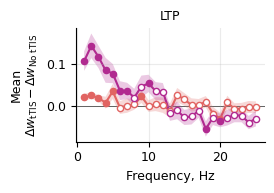

In [14]:
gained_weights = gained_weights_ltp

fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (3, 2))
ax = axs

ax.axhline(y = 0, linestyle = "-", linewidth = 0.5, color = "black", zorder = 0)

for stimulation in ["50% tTIS", "90% tTIS"]:
  dt = gained_weights[gained_weights.Stimulation == stimulation]
  sig = dt[dt.P < 0.05]
  nonsig = dt[dt.P >= 0.05]

  ax.plot(
    dt.Frequency, dt.Mean,
    color = colors[stimulation],
    zorder = 1
  )

  ax.fill_between(
    dt.Frequency,
    dt.Mean - dt.Error,
    dt.Mean + dt.Error,
    alpha = 0.25,
    color = colors[stimulation],
    edgecolor = None
  )

  ax.scatter(
    sig.Frequency,
    sig.Mean,
    color = colors[stimulation],
    label = stimulation,
    s = 20,
    zorder = 3
  )

  ax.scatter(
    nonsig.Frequency,
    nonsig.Mean,
    facecolors = "white",
    edgecolors = colors[stimulation],
    s = 20,
    alpha = 1,
    zorder = 5
  )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(alpha = 0.25)
ax.set_ylabel("Mean\n" + r"$\Delta w_{\text{tTIS}} - \Delta w_{\text{No tTIS}}$")
ax.set_xlabel("Frequency, Hz")

legend_elements = [
  Line2D([0], [0], marker = "o", color = "k", markerfacecolor = "k", markersize = 3, linestyle = "None", label = "Significant"),
  Line2D([0], [0], marker = "o", color = "k", markerfacecolor = "none", markersize = 3, linestyle = "None", label = "Not significant"),
]

ax.set_title("LTP")

plt.tight_layout()
plt.show()

In [15]:
gained_weights_ltd = []

for stimulation in ["50% tTIS", "90% tTIS"]:
  for f in frequencies:
    time_points = weights[stimulation][f].index > 9.5 * 1000
    final_weights_ti = weights[stimulation][f].iloc[time_points, :].mean(axis = 0)
    final_weights_noti = weights["No tTIS"][f].iloc[time_points, :].mean(axis = 0)

    synapses = list(
      set(np.where(final_weights_noti < 0.1 - 1e-4)[0]) &
      set(np.where(final_weights_ti < 0.1 - 1e-4)[0])
    )

    final_weights_ti = final_weights_ti[synapses]
    final_weights_noti = final_weights_noti[synapses]
    difference = final_weights_ti - final_weights_noti
    stat, p = stats.wilcoxon(final_weights_noti, final_weights_ti)


    gained_weights_ltd.append(
      pd.DataFrame({
        "Frequency": [f],
        "Stimulation": stimulation,
        "Mean": np.mean(difference),
        "Error": difference.std() / np.sqrt(difference.shape[0]),
        "P": p
      })
    )

gained_weights_ltd = pd.concat(gained_weights_ltd, ignore_index = True)

/tmp/ipykernel_90958/1817386970.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  final_weights_ti = final_weights_ti[synapses]
/tmp/ipykernel_90958/1817386970.py:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  final_weights_noti = final_weights_noti[synapses]


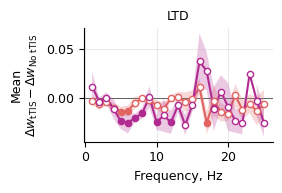

In [16]:
gained_weights = gained_weights_ltd

fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (3, 2))
ax = axs

ax.axhline(y = 0, linestyle = "-", linewidth = 0.5, color = "black", zorder = 0)

for stimulation in ["50% tTIS", "90% tTIS"]:
  dt = gained_weights[gained_weights.Stimulation == stimulation]
  sig = dt[dt.P < 0.05]
  nonsig = dt[dt.P >= 0.05]

  ax.plot(
    dt.Frequency, dt.Mean,
    color = colors[stimulation],
    zorder = 1
  )

  ax.fill_between(
    dt.Frequency,
    dt.Mean - dt.Error,
    dt.Mean + dt.Error,
    alpha = 0.25,
    color = colors[stimulation],
    edgecolor = None
  )

  ax.scatter(
    sig.Frequency,
    sig.Mean,
    color = colors[stimulation],
    label = stimulation,
    s = 20,
    zorder = 3
  )

  ax.scatter(
    nonsig.Frequency,
    nonsig.Mean,
    facecolors = "white",
    edgecolors = colors[stimulation],
    s = 20,
    alpha = 1,
    zorder = 5
  )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(alpha = 0.25)
ax.set_ylabel("Mean\n" + r"$\Delta w_{\text{tTIS}} - \Delta w_{\text{No tTIS}}$")
ax.set_xlabel("Frequency, Hz")

legend_elements = [
  Line2D([0], [0], marker = "o", color = "k", markerfacecolor = "k", markersize = 3, linestyle = "None", label = "Significant"),
  Line2D([0], [0], marker = "o", color = "k", markerfacecolor = "none", markersize = 3, linestyle = "None", label = "Not significant"),
]

ax.set_title("LTD")
plt.tight_layout()
plt.show()

In [17]:
from itertools import product

potentiation = []
for stimulation, frequency in product(weights.keys(), frequencies):
  time_points = np.where(weights[stimulation][frequency].index > 9.5 * 1000)[0]
  final = weights[stimulation][frequency].iloc[time_points, :].mean(axis = 0)
  potentiation.append(pd.DataFrame({
    "LTD": len(np.where(final < 0.1 - 1e-3)[0]) / len(final) * 100,
    "Stable": len(np.where(np.isclose(final, 0.1, atol = 1e-3))[0]) / len(final) * 100,
    "LTP": len(np.where(final > 0.1 + 1e-3)[0]) / len(final) * 100,
    "Stimulation": stimulation,
    "Frequency": [ frequency ]
  }))

potentiation = pd.concat(potentiation, ignore_index = True)

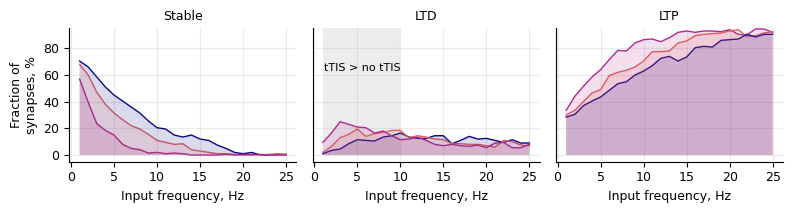

In [18]:
fig, axs = plt.subplots(nrows = 1, ncols = 3, sharey = True, figsize = (8, 2.2))

for row, type in enumerate(["Stable", "LTD", "LTP"]):
  if type == "LTP":
    stim_order = ['90% tTIS', '50% tTIS', 'No tTIS']
  else:
    stim_order = ['No tTIS', '50% tTIS', '90% tTIS']

  for stimulation in stim_order:
    data = potentiation[ potentiation.Stimulation == stimulation ][[type, "Frequency"]]
    data.columns = ["Potentiation", "Frequency"]

    axs[row ].plot(data.Frequency, data.Potentiation, color = colors[stimulation], linewidth = 1)
    axs[row].set_title(type)
    axs[row].fill_between(
      data.Frequency,
      0,
      data.Potentiation,
      alpha = 0.15,
      color = colors[stimulation],
      edgecolor = None,
      zorder = 5
    )
  
    axs[row].grid(alpha = 0.25)
    axs[row].set_xlabel("Input frequency, Hz")

    if type == "Stable":
      axs[row].set_ylabel("Fraction of\nsynapses, %")
    else:
      axs[row].tick_params(left = False, labelleft = False)
    
    axs[row].spines["top"].set_visible(False)
    axs[row].spines["right"].set_visible(False)

# Annotation for LTD higher in tTIS
axs[1].fill_between(
  np.arange(1, 11),
  0,
  100,
  alpha = 0.15,
  color = "gray",
  edgecolor = None,
  zorder = 0
)

axs[1].set_ylim(-5, 95)

axs[1].text(
  0.05, 0.7, "tTIS > no tTIS",
  transform=axs[1].transAxes,
  ha = "left",
  va = "center",
  rotation = 0,
  fontsize = 8
)

plt.tight_layout()
plt.show()

In [19]:
potentiation["LTD"]

0      1.0
1      3.5
2      4.5
3      8.5
4     11.5
      ... 
70     9.0
71     9.5
72     5.5
73     5.5
74     8.0
Name: LTD, Length: 75, dtype: float64

In [20]:
potentiation[ potentiation.Frequency < 10 ]

,LTD,Stable,LTP,Stimulation,Frequency
0,1.0,70.5,28.5,No tTIS,1
1,3.5,66.0,30.5,No tTIS,2
2,4.5,58.5,37.0,No tTIS,3
3,8.5,51.0,40.5,No tTIS,4
4,11.5,45.0,43.5,No tTIS,5
5,11.0,40.5,48.5,No tTIS,6
6,10.5,36.0,53.5,No tTIS,7
7,13.5,31.5,55.0,No tTIS,8
8,14.5,25.5,60.0,No tTIS,9
25,2.0,68.0,30.0,50% tTIS,1


## THOSE ULTIMATE HEATMAPS

In [24]:
from itertools import product
from matplotlib.colors import LinearSegmentedColormap

weight_matrix = {}
for stimulation in weights.keys():
  weight_matrix[stimulation] = []

  for frequency in frequencies:
    time_points = np.where(weights[stimulation][frequency].index > 9.9 * 1000)[0]
    final = weights[stimulation][frequency].iloc[time_points, :].mean(axis = 0)
    final = np.sort(final)
    weight_matrix[stimulation].append(final)

  weight_matrix[stimulation] = np.array(weight_matrix[stimulation])

In [27]:
weight_matrix.keys()

dict_keys(['No tTIS', '50% tTIS', '90% tTIS'])

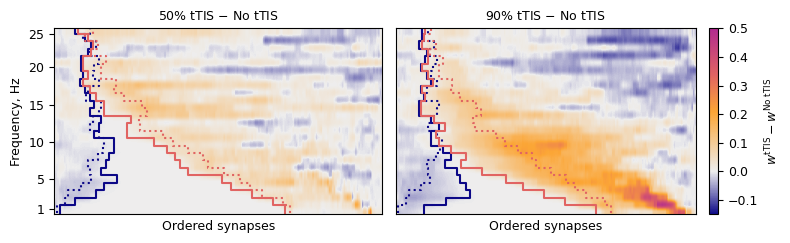

In [36]:
cmap = LinearSegmentedColormap.from_list(
  "custom_weights",
  [
    (0.0, "#0C0887FF"),
    (0.23, "#EEEEEE"),
    (0.55, "#FCA636"),
    (0.75, "#E16462"),
    (1.0, "#B12A90")
  ]
)

fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (8, 2.5))

for ax, stimulation in zip(axs, ['50% tTIS', '90% tTIS']):
  difference = weight_matrix[stimulation] - weight_matrix["No tTIS"]
  im = ax.imshow(
    difference,
    aspect = "auto",
    cmap = cmap,
    vmin = -0.15,
    vmax = 0.5
  )

  ax.set_yticks([0.5, 4.5, 9.5, 14.5, 19.5, 24])
  ax.set_yticklabels([1, 5, 10, 15, 20, 25])

  if stimulation == '50% tTIS':
    ax.set_ylabel("Frequency, Hz")
  else:
    ax.tick_params(left = False, labelleft = False)

  ax.tick_params(bottom = False, labelbottom = False)
  ax.set_xlabel("Ordered synapses")

  ax.set_title(stimulation)
  ax.set_title(rf"{stimulation} $-$ No tTIS")

  # Add outline for LTD

  outline_x = []
  outline_y = []

  for y in range(difference.shape[0]):
    row = weight_matrix[stimulation][y]
    idx = np.where(row < 0.1 - 1e-3)[0]

    if len(idx) > 0:
      outline_x.append(idx.max())
      outline_y.append(y)
      outline_x.append(idx.max())
      outline_y.append(y + 1)

  ax.plot(outline_x, outline_y, color = "#0C0887", linewidth = 1.5)

  outline_x = []
  outline_y = []

  for y in range(difference.shape[0]):
    row = weight_matrix["No tTIS"][y]
    idx = np.where(row < 0.1 - 1e-3)[0]

    if len(idx) > 0:
      outline_x.append(idx.max())
      outline_y.append(y)
      outline_x.append(idx.max())
      outline_y.append(y + 1)

  ax.plot(outline_x, outline_y, color = "#0C0887", linewidth = 1.5, linestyle=":")

  # Add outline for LTP

  outline_x = []
  outline_y = []

  for y in range(difference.shape[0]):
    row = weight_matrix[stimulation][y]
    idx = np.where(row > 0.1 + 1e-3)[0]

    if len(idx) > 0:
      outline_x.append(idx.min())
      outline_y.append(y)
      outline_x.append(idx.min())
      outline_y.append(y + 1)

  ax.plot(outline_x, outline_y, color = "#E16462", linewidth = 1.5)

  outline_x = []
  outline_y = []

  for y in range(difference.shape[0]):
    row = weight_matrix["No tTIS"][y]
    idx = np.where(row > 0.1 + 1e-3)[0]

    if len(idx) > 0:
      outline_x.append(idx.min())
      outline_y.append(y)
      outline_x.append(idx.min())
      outline_y.append(y + 1)

  ax.plot(outline_x, outline_y, color = "#E16462", linewidth = 1.5, linestyle=":")

  ax.set_ylim(24.75, -0.25)
  ax.invert_yaxis()

cbar = plt.colorbar(im, ax=axs[1], fraction=0.046, pad=0.04)
cbar.set_label(r"$w^{\text{tTIS}} - w^{\text{No tTIS}}$")

plt.tight_layout()
plt.show()

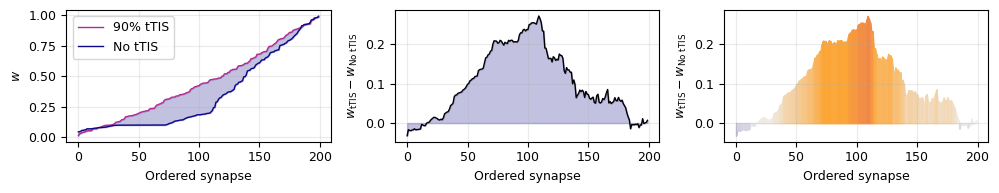

: 

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

stimulation = "90% tTIS"
frequency = 9

fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize = (10, 2))

ax = axs[0]
ax.grid(alpha = 0.25)
ax.plot(np.arange(0, 200), weight_matrix[stimulation][frequency], color = colors[stimulation], linewidth = 1, label = stimulation)
ax.plot(np.arange(0, 200), weight_matrix["No tTIS"][frequency], color = colors["No tTIS"], linewidth = 1, label = "No tTIS")
ax.fill_between(np.arange(0, 200), weight_matrix[stimulation][frequency], weight_matrix["No tTIS"][frequency], color = colors["No tTIS"], alpha = 0.25)
ax.set_ylabel(r"$w$")
ax.set_xlabel("Ordered synapse")
ax.legend()

ax = axs[1]
ax.grid(alpha = 0.25)
ax.plot(np.arange(0, 200), weight_matrix[stimulation][frequency] - weight_matrix["No tTIS"][frequency], color = "black", linewidth = 1)
ax.fill_between(np.arange(0, 200), 0, weight_matrix[stimulation][frequency] - weight_matrix["No tTIS"][frequency], color = colors["No tTIS"], alpha = 0.25)
ax.set_ylabel(r"$w_{\text{tTIS}} - w_{\text{No tTIS}}$")
ax.set_xlabel("Ordered synapse")

ax = axs[2]
ax.set_ylabel(r"$w_{\text{tTIS}} - w_{\text{No tTIS}}$")
ax.set_xlabel("Ordered synapse")
x = np.arange(0, 200)
values = weight_matrix[stimulation][frequency] - weight_matrix["No tTIS"][frequency]
y1 = values
y2 = np.zeros_like(values)

norm = mcolors.Normalize(vmin = -0.15, vmax = 0.5)
for i in range(len(x) - 1):
  color = cmap(norm(values[i]))
  ax.fill_between(
    x[i:i+2],
    y1[i:i+2],
    y2[i:i+2],
    color=color
  )

ax.grid(alpha = 0.25)

plt.tight_layout()
plt.show()